<a href="https://colab.research.google.com/github/Deathbot545/Sri-lanka-Savings/blob/main/DW_CW_022.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Protecting household savings in Sri Lanka
### A one-year deposit decision and the risk of needing to sell shares early
**Decision maker:** a household setting aside Rs. 100,000 for a rupee expense. **Decision:** compare one-year maturity proceeds and the risk borne by the portion held in shares. **Evidence:** official historical benchmarks and a separate company-day risk study. All monetary results are gross of tax and fees.
  
Run the notebook in order with Python 3, pandas, NumPy, matplotlib and scikit-learn. The first run downloads a public CSV into the working directory. All tables and charts below also have saved outputs.

**Running in Colab.** Upload the accompanying project ZIP into the runtime's Files panel. In a temporary setup cell run `!unzip -oq Sri_Lanka_Savings_Updated.zip -d /content/savings_project` followed on a separate line by `%cd /content/savings_project`. If needed, install dependencies with `%pip install pymupdf`. Run the analysis cells in order. The pinned stock CSV and SEC/DCS publications are downloaded on first use. The ZIP contains the CBSL source-table extracts needed for both holding periods.

## 1 · Problem, scope and success criteria
A known bill creates two risks. Inflation can erode the purchasing power of a deposit at maturity. An unexpected expense can also force an equity holder to sell after a price fall. For the first risk, compare actual year-end benchmark wealth with the starting purchasing power. For the second, estimate the probability of a share closing at least 5% lower five market sessions later. The latter is a price-risk indicator for individual shares, not an allocation signal for the whole market.
  
Savers care about the size of a shortfall; advisers need intelligible scenarios; banks quote maturity proceeds; equity investors face market and liquidity risk. A useful risk model should beat the training event frequency on held-out Brier score (lower is better) and rank risky cases above the test prevalence on average precision. These criteria are specified before evaluation.

## 2 · Acquire and audit the stock data
Jayawardana and colleagues publish their University of Moratuwa event-study data under CC BY 4.0. Each record is a quoted security on a date. Voting and non-voting shares may have different symbols. This notebook checks the exact bytes used and prints the download URL. To obtain the CSV manually, save the linked file as stock_prices.csv beside the notebook.

In [ ]:
from pathlib import Path
from urllib.request import urlretrieve
import hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
url = 'https://huggingface.co/datasets/tharu-jwd/cse-market-data/resolve/669594502b85772c7b7c853067afde91402e3c2a/stock_prices.csv'
path = Path('stock_prices.csv')
if not path.exists():
    urlretrieve(url, path)
digest = hashlib.sha256(path.read_bytes()).hexdigest()
assert digest == 'b7852390b371939ebf9927a1a37092b3ae00cc227061ee528b9ac41aafda57a4'
raw = pd.read_csv(path, parse_dates=['date'])
print(url, digest, sep='\n')
print(raw.shape, raw.symbol.nunique(), raw.date.nunique(), raw.date.min(), raw.date.max())
print(raw.isna().sum().to_string())

https://huggingface.co/datasets/tharu-jwd/cse-market-data/resolve/669594502b85772c7b7c853067afde91402e3c2a/stock_prices.csv
b7852390b371939ebf9927a1a37092b3ae00cc227061ee528b9ac41aafda57a4
(71044, 7) 289 257 2025-02-03 00:00:00 2026-02-27 00:00:00
symbol    0
date      0
open      0
high      0
low       0
close     0
volume    0


In [ ]:
keys = ['symbol','date']
assert not raw.duplicated(keys).any(), 'Investigate duplicate security-date keys'
valid = (raw.low > 0) & (raw.volume >= 0) & (raw.low <= raw[['open','close']].min(axis=1)) & (raw.high >= raw[['open','close']].max(axis=1))
print('OHLC/volume exceptions:', (~valid).sum(), 'zero-volume quotes:', raw.volume.eq(0).sum())
quotes = raw.loc[valid].copy()
calendar = pd.DatetimeIndex(sorted(raw.date.unique()))
def wide(field):
    return quotes.pivot(index='date', columns='symbol', values=field).reindex(calendar)
price = wide('close')
volume = wide('volume')
traded = price.where(volume > 0)
returns = traded.pct_change(fill_method=None)
print('Largest absolute adjacent-session changes:')
print(returns.abs().stack().nlargest(8).to_string())

OHLC/volume exceptions: 0 zero-volume quotes: 75
Largest absolute adjacent-session changes:
            symbol    
2025-10-09  COLO.N0000    8.709091
2025-10-08  CIC.X0000     3.962121
2025-04-07  CSF.N0000     1.000000
2025-05-02  CSF.N0000     1.000000
2025-05-08  CSF.N0000     1.000000
2025-05-16  CSF.N0000     1.000000
2025-05-27  CSF.N0000     1.000000
2025-05-29  CSF.N0000     1.000000


Missing security-days stay missing. Zero volume gives no evidence that a saver could transact at the close. Returns require two consecutive market dates with observed trading. Extreme changes are retained and flagged because splits or other corporate actions could mimic losses; price changes here exclude dividend income. The official household benchmark below includes reinvested dividends. pandas reshapes this small in-memory panel without distributed infrastructure.

## 3 · Historical decision at the onset of the 2022 crisis
The benchmark uses three official publications. The cell downloads the SEC annual report and DCS inflation release into `benchmark_sources/` on first use and extracts the labelled observations. Install PyMuPDF once with `%pip install pymupdf` if needed. For the FD range the project includes a machine-extracted source file of the header and December 2021 row of the CBSL table. The parser selects the one-year columns by name. This preserves the source row for inspection even if CBSL blocks automated downloads.

[SEC annual report, p. 75](https://www.sec.gov.lk/wp-content/uploads/2025/07/SEC-AR-2024.pdf) · [CBSL statistical appendix, Table 123](https://www.cbsl.gov.lk/sites/default/files/cbslweb_documents/publications/annual_report/2022/en/15_Appendix.pdf) · [DCS December 2022 NCPI release](https://www.statistics.gov.lk/Resource/en/InflationAndPrices/NCPI/NCPI_December_2022.pdf)

Compare one year from December 2021 with interest paid at maturity. Rs. 100,000 and the 50/50 split are scenario choices. Results are before tax and fees.

ASTRI levels: {2021: 16423.75, 2022: 11404.6, 2023: 14617.77, 2024: 23067.59}
Opening one-year FD range (%): 1.50 to 10.00
December 2022 national inflation (%): 59.2
               nominal LKR  opening-date LKR  purchasing-power shortfall
Equity             69440.0           43618.0                     56382.0
FD low            101500.0           63756.0                     36244.0
FD high           110000.0           69095.0                     30905.0
Mix / low FD       85470.0           53687.0                     46313.0
Mix / high FD      89720.0           56357.0                     43643.0
Annual market returns (%) {2022: -30.56, 2023: 28.17, 2024: 57.81}


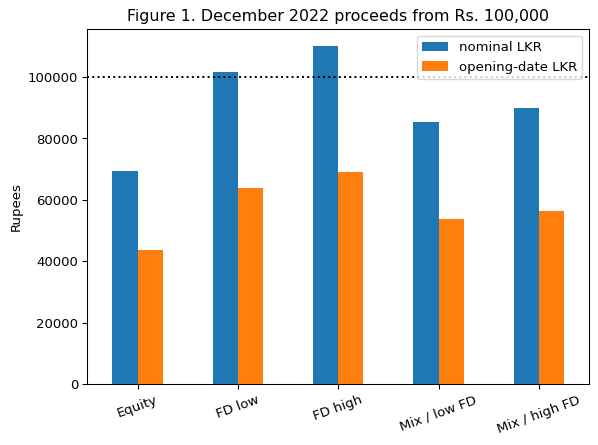

In [ ]:
import re
from pathlib import Path
from urllib.request import urlopen
import pymupdf

def publication_page(url, page, layout=False):
    cache = Path("benchmark_sources")
    cache.mkdir(exist_ok=True)
    path = cache / url.rsplit("/", 1)[-1]
    if not path.exists():
        with urlopen(url, timeout=90) as response:
            data = response.read()
        if not data.startswith(b"%PDF"):
            raise ValueError(f"Expected a PDF from {url}")
        path.write_bytes(data)
    with pymupdf.open(path) as pdf:
        page_text = pdf[page - 1].get_text(sort=layout)
        return page_text if layout else " ".join(page_text.split())

sec_url = "https://www.sec.gov.lk/wp-content/uploads/2025/07/SEC-AR-2024.pdf"
dcs_url = "https://www.statistics.gov.lk/Resource/en/InflationAndPrices/NCPI/NCPI_December_2022.pdf"
market_page = publication_page(sec_url, 77)  # printed page 75
row = re.search(r"Total Return Index on ASPI \(ASTRI\) ((?:[\d,]+\.\d{2} ){5})", market_page)
if row is None:
    raise ValueError("Cannot identify the five annual ASTRI observations.")
levels = [float(value.replace(",", "")) for value in row[1].split()]
index = pd.Series(levels, index=range(2020, 2025), name="ASTRI").loc[2021:2024]

# Machine-extracted CBSL Table 123 snapshot. Preserve the complete rate row and header.
fd_snapshot = Path("benchmark_sources/CBSL_2021.txt").read_text().strip()
def fields(line):
    return [field.strip() for field in line.strip("|").split("|")]
header, observation = map(fields, fd_snapshot.splitlines())
rates = dict(zip(header, observation, strict=True))
assert rates["End of period"] == "2021 December"
fd_low = 1 + float(rates["1-year Min."]) / 100
fd_high = 1 + float(rates["1-year Max."]) / 100

inflation_page = publication_page(dcs_url, 1)
match = re.search(r"on Year-on-Year basis is ([\d.]+)% in December 2022", inflation_page)
if match is None:
    raise ValueError("Cannot identify the December 2022 national inflation rate.")
inflation_factor = 1 + float(match[1]) / 100
print("ASTRI levels:", index.to_dict())
print("Opening one-year FD range (%):", rates["1-year Min."], "to", rates["1-year Max."])
print("December 2022 national inflation (%):", match[1])

capital = 100000
equity = index.loc[2022] / index.loc[2021]
gross = pd.Series({'Equity':equity, 'FD low':fd_low, 'FD high':fd_high,
                   'Mix / low FD':(equity+fd_low)/2, 'Mix / high FD':(equity+fd_high)/2})
wealth = pd.DataFrame({'nominal LKR':capital*gross, 'opening-date LKR':capital*gross/inflation_factor})
wealth['purchasing-power shortfall'] = (capital-wealth['opening-date LKR']).clip(lower=0)
print(wealth.round().to_string())
print('Annual market returns (%)', (100*index.pct_change()).dropna().round(2).to_dict())
wealth.iloc[:,:2].plot.bar(title='Figure 1. December 2022 proceeds from Rs. 100,000', ylabel='Rupees',rot=20)
plt.axhline(capital,color='black',ls=':'); plt.tight_layout()

The deposit preserved more purchasing power across the quoted range in this crisis year. Even the upper rate left a real shortfall. Recovery returns describe a different starting date; rolling an FD through recovery would require the rate actually available at each renewal.

## 4 · Explore the security panel
Look for changing coverage, large cross-sectional price moves, concentration of illiquidity, market-wide drawdowns and co-movement. A median daily return describes the typical observed traded share. It is not the return on a replicable index.

Median active names: 278.0 lowest: 165
Lowest median-return dates: {Timestamp('2025-12-01 00:00:00'): -0.0389, Timestamp('2025-04-07 00:00:00'): -0.0338, Timestamp('2025-02-05 00:00:00'): -0.0312, Timestamp('2025-06-23 00:00:00'): -0.0222, Timestamp('2025-11-24 00:00:00'): -0.0186}


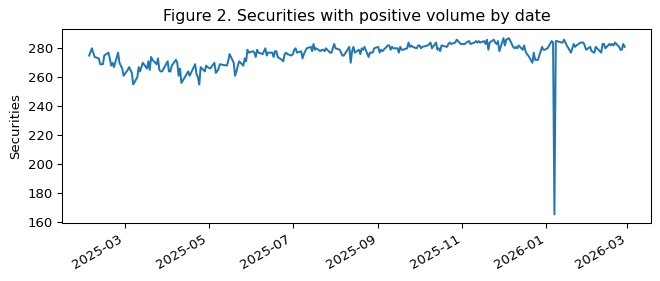

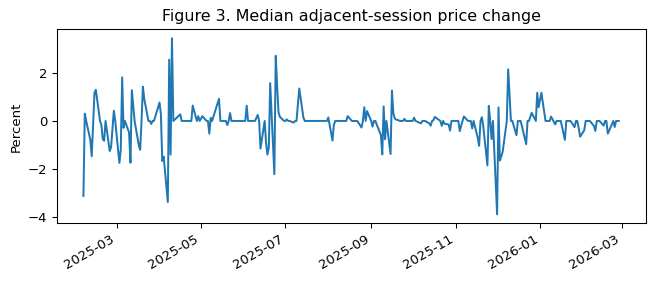

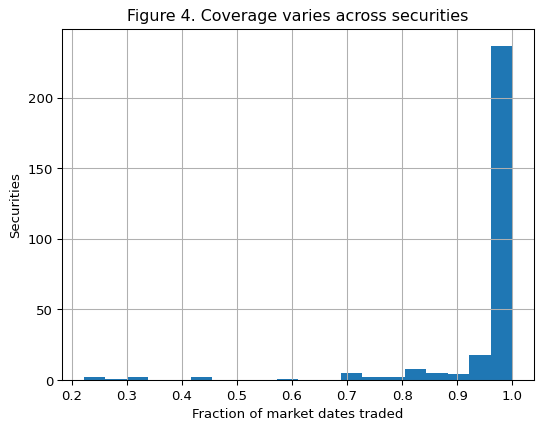

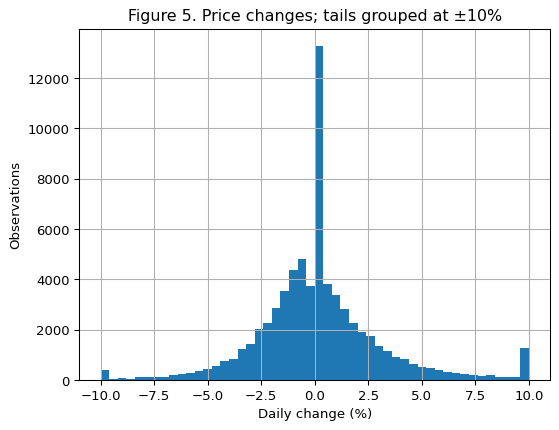

In [ ]:
active = traded.count(axis=1)
active.plot(title='Figure 2. Securities with positive volume by date',ylabel='Securities',figsize=(8,3))
plt.figure()
daily = returns.median(axis=1)
daily.mul(100).plot(title='Figure 3. Median adjacent-session price change',ylabel='Percent',figsize=(8,3))
plt.figure()
coverage = traded.count()/len(calendar)
coverage.hist(bins=20)
plt.title('Figure 4. Coverage varies across securities'); plt.xlabel('Fraction of market dates traded'); plt.ylabel('Securities')
plt.figure()
(100*returns.stack()).clip(-10,10).hist(bins=50)
plt.title('Figure 5. Price changes; tails grouped at ±10%'); plt.xlabel('Daily change (%)'); plt.ylabel('Observations')
print('Median active names:', active.median(), 'lowest:', active.min())
print('Lowest median-return dates:', daily.nsmallest(5).round(4).to_dict())

## 5 · Construct an early-sale risk target
At the close of day t, estimate whether the closing price at t+5 will be at least 5% below today's price. This captures endpoint loss; it misses temporary declines inside the window. Construct the horizon on the common market calendar before dropping any gaps. A quote on each endpoint must have positive volume. Securities with insufficient trading history are excluded, creating a bias toward liquid shares.

(62489, 7) {0: 56367, 1: 6122}
            one_day  five_day  volatility  range  log_volume  forward  loss
one_day        1.00      0.37        0.01   0.03        0.08    -0.10  0.08
five_day       0.37      1.00        0.14   0.08        0.13    -0.09  0.09
volatility     0.01      0.14        1.00   0.49       -0.05    -0.02  0.16
range          0.03      0.08        0.49   1.00        0.24    -0.02  0.13
log_volume     0.08      0.13       -0.05   0.24        1.00     0.02  0.00
forward       -0.10     -0.09       -0.02  -0.02        0.02     1.00 -0.51
loss           0.08      0.09        0.16   0.13        0.00    -0.51  1.00
Median eligible shares/date: 262.0


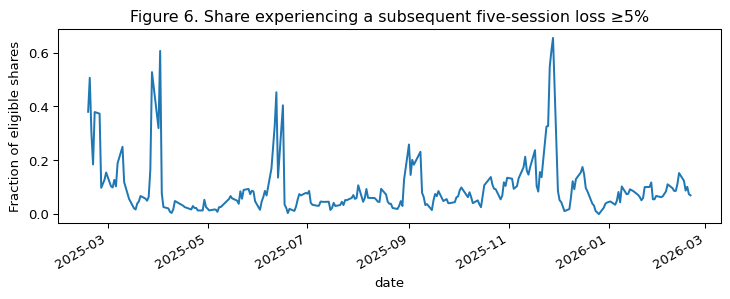

In [ ]:
horizon = 5
features = {'one_day': returns, 'five_day': traded/traded.shift(5)-1,
            'volatility': returns.rolling(10,min_periods=8).std(),
            'range': (wide('high')-wide('low'))/traded,
            'log_volume': np.log1p(volume)}
forward = traded.shift(-horizon)/traded-1
panel = pd.concat({k:v.stack() for k,v in {**features,'forward':forward}.items()},axis=1).dropna()
panel.index.names=['date','symbol']
panel['loss'] = (panel.forward <= -0.05).astype(int)
print(panel.shape, panel.loss.value_counts().to_dict())
print(panel.corr(method='spearman').round(2).to_string())
panel.groupby(level='date').loss.mean().plot(title='Figure 6. Share experiencing a subsequent five-session loss ≥5%',ylabel='Fraction of eligible shares',figsize=(9,3))
print('Median eligible shares/date:',panel.groupby(level='date').size().median())

## 6 · Train, validate and test
Allocate entire dates together. Purge the last five training and validation start dates before each boundary so forward labels cannot cross it. Fit the scaler only on training rows. The model sees numerical features only; ticker is a grouping key. Logistic regression offers an interpretable linear relationship; a tree captures nonlinear thresholds. Choose regularisation or depth by validation Brier score. Compare against a constant training-frequency forecast.

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
days = panel.index.get_level_values('date')
v, t = calendar[int(.60*len(calendar))], calendar[int(.80*len(calendar))]
end_dates = days.map(pd.Series(calendar,index=calendar).shift(-horizon))
train = panel[(end_dates<v)]
val = panel[(days>=v)&(end_dates<t)]
test = panel[days>=t]
cols = list(features)
for name,part in [('train',train),('validation',val),('test',test)]:
    print(name,len(part),part.index.get_level_values(0).min().date(),part.index.get_level_values(0).max().date(), round(part.loss.mean(),3))

train 35222 2025-02-17 2025-09-18 0.091
validation 12601 2025-09-26 2025-12-03 0.143
test 11997 2025-12-12 2026-02-20 0.08


Logistic validation Brier by setting: [('0.1', 0.12186), ('1', 0.12187), ('10', 0.12187)] chosen: 0.1
Tree validation Brier by setting: [('2', 0.12219), ('3', 0.12168), ('5', 0.12091)] chosen: 5
Validation-selected family: Tree
                     Brier  Average precision  ROC AUC
Training frequency  0.0737             0.0799   0.5000
Logistic            0.0716             0.1963   0.7088
Tree                0.0699             0.1804   0.7101


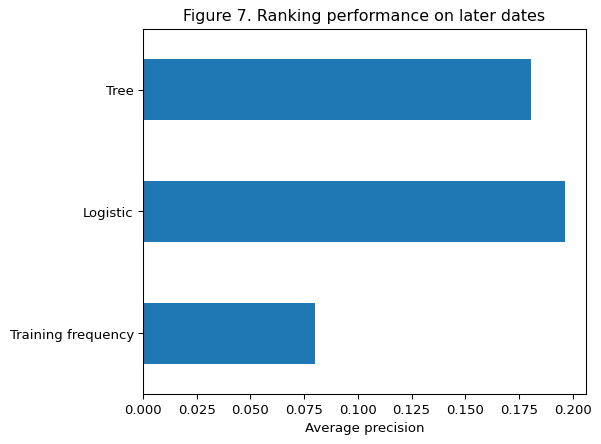

In [ ]:
candidates = {'Logistic': [(str(c), make_pipeline(StandardScaler(),LogisticRegression(C=c,max_iter=500))) for c in [.1,1,10]],
              'Tree': [(str(d),DecisionTreeClassifier(max_depth=d,min_samples_leaf=150,random_state=22)) for d in [2,3,5]]}
pred = {'Training frequency': np.full(len(test),train.loss.mean())}
validation_scores = {}
for family, options in candidates.items():
    records=[]
    for setting,model in options:
        model.fit(train[cols],train.loss)
        probability=model.predict_proba(val[cols])[:,1]
        records.append((brier_score_loss(val.loss,probability),setting,model))
    score,setting,winner=min(records,key=lambda row:row[0])
    print(family, 'validation Brier by setting:', [(s,round(b,5)) for b,s,_ in records], 'chosen:',setting)
    validation_scores[family]=score
    pred[family]=winner.predict_proba(test[cols])[:,1]
selected = min(validation_scores,key=validation_scores.get)
metrics = pd.DataFrame({k:{'Brier':brier_score_loss(test.loss,p),'Average precision':average_precision_score(test.loss,p),
                            'ROC AUC':roc_auc_score(test.loss,p)} for k,p in pred.items()}).T
print('Validation-selected family:',selected)
print(metrics.round(4).to_string())
metrics['Average precision'].plot.barh(title='Figure 7. Ranking performance on later dates',xlabel='Average precision')
plt.tight_layout()

In [ ]:
scores = pd.DataFrame({'date':test.index.get_level_values('date'),'score':pred[selected], 'loss':test.loss.to_numpy()})
scores['high_risk'] = scores.groupby('date').score.rank(pct=True,method='average') >= .9
print(scores.groupby('high_risk').agg(observations=('loss','size'),mean_forecast=('score','mean'),observed_loss=('loss','mean')).round(3))
print('Test Brier improvement vs constant:',round(metrics.loc['Training frequency','Brier']-metrics.loc[selected,'Brier'],4))
print('Test dates:',scores.date.nunique())

           observations  mean_forecast  observed_loss
high_risk                                            
False             10814          0.071          0.064
True               1183          0.250          0.229
Test Brier improvement vs constant: 0.0038
Test dates: 47


## 6A · A second one-year decision using the large dataset
A household considering a single listed share in February 2025 could also have opened a twelve-month deposit. Compare each eligible share over the same month-end holding period. CBSL's February 2025 commercial-bank range was 2.50%–12.00%. The national price index rose from 206.2 to 209.4. These inputs come from the [CBSL weekly indicators, 17 April 2025](https://www.cbsl.gov.lk/sites/default/files/cbslweb_documents/statistics/wei/WEI_20250417_e.pdf) and the [DCS February 2026 NCPI release](https://www.statistics.gov.lk/Resource/en/InflationAndPrices/NCPI/NCPI_20260323E.pdf). Use these releases for retrospective evaluation. Their eventual publications cannot be used as earlier forecasts.

In [ ]:
start = calendar[calendar.to_period('M') == '2025-02'][-1]
finish = calendar[calendar.to_period('M') == '2026-02'][-1]
entry = traded.loc[start].dropna()
exit_prices = traded.loc[finish].reindex(entry.index)
annual = (exit_prices / entry - 1).dropna()
print('Entry and exit:', start.date(), finish.date())
print('Positive volume at entry:', len(entry), 'observable at both ends:', len(annual))
print('Unavailable at exit:', exit_prices.isna().sum())
print(annual.describe(percentiles=[.1,.25,.5,.75,.9]).round(3))

Entry and exit: 2025-02-28 2026-02-27
Positive volume at entry: 261 observable at both ends: 255
Unavailable at exit: 6
count    255.000
mean       0.875
std        1.139
min       -0.347
10%       -0.000
25%        0.215
50%        0.520
75%        1.138
90%        2.075
max        7.673
dtype: float64


### What did the distribution mean in rupees?
This comparison follows a holder of one security. Each share class counts once, irrespective of market capitalisation. A quoted close is a valuation assumption. Dividends, fees and unverified share splits limit the interpretation of price-only changes. Exit coverage is reported because excluding unavailable shares can overstate attainable outcomes.

February NCPI by year: {2025: 206.2, 2026: 209.4}
Published FD range: 2.50 - 12.00
                          Nominal rupees  Feb 2025 rupees
One-year FD, low                102500.0         100934.0
One-year FD, high               112000.0         110288.0
Share at 10th percentile         99986.0          98458.0
Median share                    152036.0         149713.0
Share at 90th percentile        307509.0         302810.0
Fraction clearing 2.50%: 85.9%
Fraction clearing 12.00%: 78.8%
Fraction clearing 1.55%: 89.0%


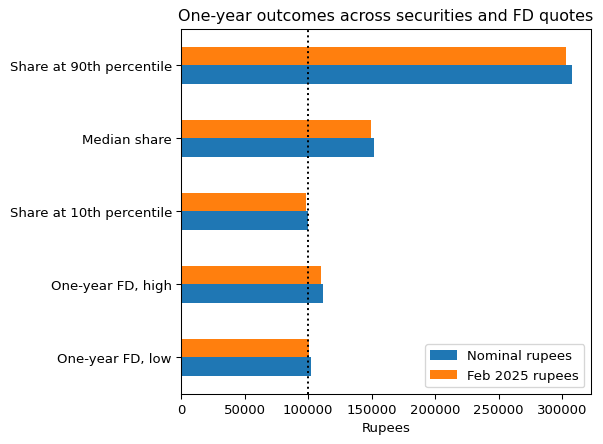

In [ ]:
from xml.etree import ElementTree

# The source extract retains the publication's column dates and product label.
table = ElementTree.parse("benchmark_sources/CBSL_2025.html")
header, product = table.findall(".//tr")
quoted = dict(zip([x.text for x in header], [x.text for x in product], strict=True))
assert quoted[None] == "One Year Fixed Deposits"
fd_rates = tuple(float(value.strip()) / 100 for value in quoted["February 2025"].split("-"))
assert len(fd_rates) == 2 and 0 <= fd_rates[0] <= fd_rates[1] < 1

release_url = "https://www.statistics.gov.lk/Resource/en/InflationAndPrices/NCPI/NCPI_20260323E.pdf"
ncpi_table = publication_page(release_url, 2, layout=True)
year = None
february_ncpi = {}
for line in ncpi_table.splitlines():
    label = line.strip()
    if re.fullmatch(r"20[0-9]{2}", label):
        year = int(label)
    row = re.match(r"February\s+(\d+\.\d+)\s+", label)
    if row and year in (2025, 2026):
        if year in february_ncpi:
            raise ValueError(f"Duplicate February observation for {year}")
        february_ncpi[year] = float(row[1])
inflation_factor = february_ncpi[2026] / february_ncpi[2025]
print("February NCPI by year:", february_ncpi)
print("Published FD range:", quoted["February 2025"])

annual_cases = pd.Series({'One-year FD, low':(1 + fd_rates[0]),'One-year FD, high':(1 + fd_rates[1]),
                          'Share at 10th percentile':1+annual.quantile(.1),
                          'Median share':1+annual.median(),
                          'Share at 90th percentile':1+annual.quantile(.9)})
annual_wealth = pd.DataFrame({'Nominal rupees':capital*annual_cases,
                              'Feb 2025 rupees':capital*annual_cases/inflation_factor})
print(annual_wealth.round().to_string())
for hurdle in [*fd_rates, inflation_factor-1]:
    print(f'Fraction clearing {hurdle:.2%}: {(annual>hurdle).mean():.1%}')
annual_wealth.plot.barh(title='One-year outcomes across securities and FD quotes',xlabel='Rupees')
plt.axvline(capital,color='black',ls=':'); plt.tight_layout()

### How sensitive is the answer to missing exit prices?
Bound the fraction of entry securities beating each FD by treating every missing exit first as a failure and then as a success. These are bounds on a count, not guesses about the value of a delisted share.

In [ ]:
bounds = []
for rate in fd_rates:
    observed_wins = annual.gt(rate).sum()
    bounds.append([rate, observed_wins/len(entry),(observed_wins+exit_prices.isna().sum())/len(entry)])
print(pd.DataFrame(bounds,columns=['FD rate','Minimum win fraction','Maximum win fraction']).round(3))

   FD rate  Minimum win fraction  Maximum win fraction
0    0.025                 0.839                 0.862
1    0.120                 0.770                 0.793


### How much could equity exposure change a household's shortfall?
For each eligible share, simulate investing a fixed portion in that share and the remainder in an FD at the start. Hold to the common endpoint. The quantiles describe dispersion across share choices in one historical year. They are not probabilities for the next year.

 FD rate  Equity weight  P10 real LKR  Median real LKR  Shortfall fraction
   0.025           0.00    100933.620       100933.620               0.000
   0.025           0.25    100314.775       113128.420               0.094
   0.025           0.50     99695.931       125323.219               0.102
   0.025           0.75     99077.086       137518.019               0.110
   0.025           1.00     98458.242       149712.819               0.110
   0.120           0.00    110288.443       110288.443               0.000
   0.120           0.25    107330.893       120144.537               0.008
   0.120           0.50    104373.343       130000.631               0.055
   0.120           0.75    101415.792       139856.725               0.086
   0.120           1.00     98458.242       149712.819               0.110


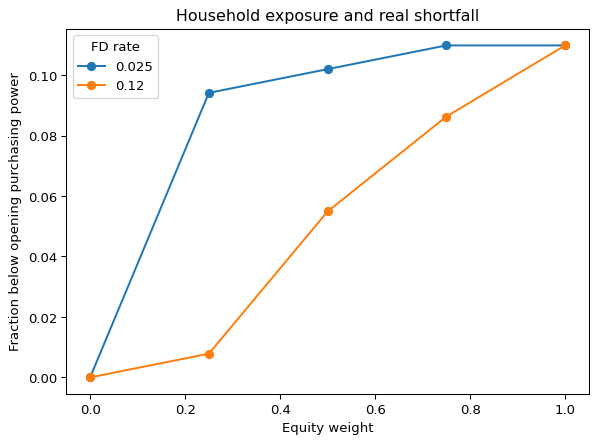

In [ ]:
scenarios=[]
for rate in fd_rates:
    for weight in [0,.25,.5,.75,1]:
        real = capital*((1-weight)*(1+rate)+weight*(1+annual))/inflation_factor
        scenarios.append([rate,weight,real.quantile(.1),real.median(),real.lt(capital).mean()])
alloc = pd.DataFrame(scenarios,columns=['FD rate','Equity weight','P10 real LKR','Median real LKR','Shortfall fraction'])
print(alloc.round(3).to_string(index=False))
alloc.pivot(index='Equity weight',columns='FD rate',values='Shortfall fraction').plot(marker='o',ylabel='Fraction below opening purchasing power',title='Household exposure and real shortfall')
plt.tight_layout()

### From a maturity balance to the path taken
Two shares can close the year at similar values after very different declines. For a household forced to sell early, the largest fall from a previously observed peak can matter more than the eventual gain. Missing quotes can hide deeper losses.

     Year price change  Worst observed drawdown  Traded dates
0.1             -0.000                   -0.340         231.4
0.5              0.520                   -0.207         240.0
0.9              2.075                   -0.135         241.0


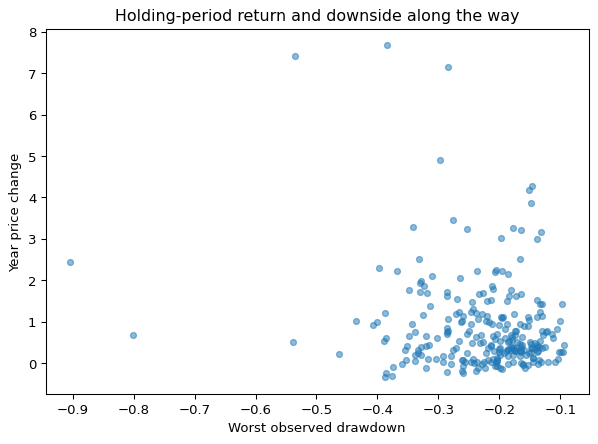

In [ ]:
paths = traded.loc[start:finish,annual.index]
drawdowns = paths/paths.cummax()-1
worst = drawdowns.min()
risk_summary = pd.concat([annual.rename('Year price change'),worst.rename('Worst observed drawdown'),paths.count().rename('Traded dates')],axis=1)
print(risk_summary.quantile([.1,.5,.9]).round(3))
risk_summary.plot.scatter(x='Worst observed drawdown',y='Year price change',alpha=.5,title='Holding-period return and downside along the way')
plt.tight_layout()

## 6B · Model diagnostics and reliability
A probability forecast can rank securities accurately while systematically understating how often losses occur. Group predictions by score and compare the forecast mean with the actual loss frequency. The test period remains untouched by model selection.

                                   n  forecast  actual
band                                                  
(0.012299999999999998, 0.0445]  4046     0.037   0.030
(0.0445, 0.064]                  849     0.058   0.039
(0.064, 0.078]                  2320     0.069   0.068
(0.078, 0.116]                  3244     0.106   0.099
(0.116, 0.461]                  1538     0.230   0.211


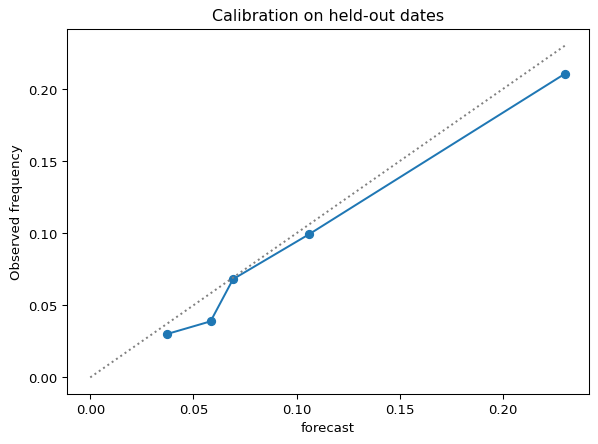

In [ ]:
calib = scores.copy()
calib['band'] = pd.qcut(calib.score,5,duplicates='drop')
reliability = calib.groupby('band',observed=True).agg(n=('loss','size'),forecast=('score','mean'),actual=('loss','mean'))
print(reliability.round(3))
ax = reliability.plot(x='forecast',y='actual',marker='o',legend=False,ylabel='Observed frequency',title='Calibration on held-out dates')
ax.plot([0,reliability.forecast.max()],[0,reliability.forecast.max()],ls=':',color='grey')
plt.tight_layout()

### How costly are missed losses and false alarms?
Use the validation distribution to set an alert threshold at its 90th percentile. This represents a limited review budget. Tree scores are discrete, so ties may produce more alerts than the intended fraction. Avoid selecting a cut-off using test outcomes.

In [ ]:
from sklearn.metrics import confusion_matrix
family_options = candidates[selected]
best_model = min((model for setting,model in family_options),key=lambda model:brier_score_loss(val.loss,model.predict_proba(val[cols])[:,1]))
cutoff = np.quantile(best_model.predict_proba(val[cols])[:,1],.90)
alert = scores.score >= cutoff
tn,fp,fn,tp = confusion_matrix(scores.loss,alert,labels=[0,1]).ravel()
print(pd.DataFrame([[tn,fp],[fn,tp]],index=['No loss event','Loss event'],columns=['No alert','Alert']))
print('Alert fraction', round(alert.mean(),3), 'precision', round(tp/max(tp+fp,1),3),'recall',round(tp/max(tp+fn,1),3))

               No alert  Alert
No loss event     10077    961
Loss event          671    288
Alert fraction 0.104 precision 0.231 recall 0.3


### Does the result depend on the month?
Calculate the improvement over the constant forecast separately for each test month. A negative improvement flags a period when the extra model complexity hurt probability accuracy. Partial months and common shocks restrict comparisons.

In [ ]:
monthly = []
for month,part in scores.groupby(scores.date.dt.to_period('M')):
    loss_baseline = np.mean((part.loss-train.loss.mean())**2)
    loss_model = np.mean((part.loss-part.score)**2)
    monthly.append([str(month),part.date.nunique(),len(part),part.loss.mean(),loss_baseline-loss_model])
print(pd.DataFrame(monthly,columns=['Month','Dates','Security-days','Event rate','Brier improvement']).round(4).to_string(index=False))

  Month  Dates  Security-days  Event rate  Brier improvement
2025-12     13           3233      0.0770             0.0067
2026-01     20           4997      0.0714             0.0016
2026-02     14           3767      0.0937             0.0042


### Which signals does the selected model rely on?
Permutation importance measures the reduction in forecast quality after disrupting a feature. Shuffle within each date so that daily market conditions are preserved. Correlated predictors can substitute for one another; importance is predictive, not causal.

volatility    0.00196
range         0.00166
five_day      0.00070
one_day       0.00055
log_volume   -0.00009
dtype: float64


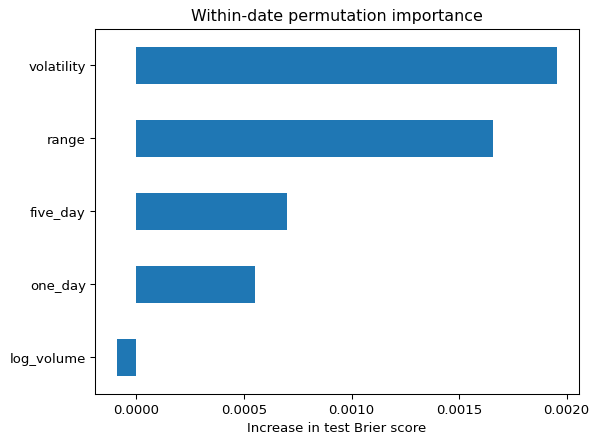

In [ ]:
rng = np.random.default_rng(22)
imp = {}
for field in cols:
    shuffled = test[cols].copy()
    shuffled[field] = shuffled[field].groupby(level='date').transform(lambda values:rng.permutation(values))
    disrupted = best_model.predict_proba(shuffled)[:,1]
    imp[field] = brier_score_loss(test.loss,disrupted)-metrics.loc[selected,'Brier']
print(pd.Series(imp).sort_values(ascending=False).round(5))
pd.Series(imp).sort_values().plot.barh(title='Within-date permutation importance',xlabel='Increase in test Brier score')
plt.tight_layout()

### Sensitivity to the household's definition of loss
A 5% threshold is a modelling decision. Recalculate the observed event fractions for different loss sizes on the identical later sample. These prevalence figures quantify sensitivity without pretending the fitted 5% model predicts different targets.

In [ ]:
for threshold in [.02,.05,.10]:
    observed = test.forward.le(-threshold)
    print(f'Loss of at least {threshold:.0%}: {observed.sum():,} cases ({observed.mean():.1%})')
assert (train.index.get_level_values('date').max()<val.index.get_level_values('date').min())
assert (val.index.get_level_values('date').max()<test.index.get_level_values('date').min())
assert np.isfinite(metrics.to_numpy()).all()

Loss of at least 2%: 3,304 cases (27.5%)
Loss of at least 5%: 959 cases (8.0%)
Loss of at least 10%: 162 cases (1.4%)


### Putting both holding periods together
From February 2025 to February 2026, 78.8% of the 255 securities with traded quotes at both ends cleared the high FD hurdle on price change alone. The median change was 52.0%, while the 10th percentile was -0.0%. A saver choosing a single security faced substantial dispersion around the median. For the 50/50 scenario at the high FD rate, the purchasing-power shortfall fraction across eligible share choices was 5.5%. This result depends on having an observable exit and access to the assumed rate.

The 2022 crisis case answers a broad-market question using a dividend-inclusive index. The later panel answers a single-security question using price-only changes. Differences between these examples cannot identify the effect of a recession or establish that either strategy dominates over future cycles.

## 7 · Interpretation and decision
The validation-selected Tree achieved test Brier 0.0699 versus 0.0737 for the constant forecast. Its average precision was 0.180 against event prevalence 0.080. Read the ranking and probability scores together: choosing risky names and giving them accurate probabilities are different tasks. Ties can change the size of the upper risk group. These scores describe one later period, with many shares exposed to the same market shocks and overlapping outcomes. They cannot establish reliability in an independent economic crisis.

**Household with a fixed deadline.** Match guaranteed-at-maturity nominal proceeds under the specific deposit contract to the expected bill. Check whether the expense rises with prices and whether early withdrawal is allowed. In the 2022 example the deposit reduced the shortfall, but every allocation examined fell short of maintaining purchasing power.

**Household with an equity allocation.** Use observed loss frequencies to explain possible forced-sale risk and maintain liquidity for near-term needs. Prices of individual shares exclude dividends and may be affected by corporate actions. A five-session warning cannot decide when to switch an entire portfolio between equities and deposits.

**What would change the recommendation?** Obtain long, matched monthly ASTRI and dated one-year FD quotes spanning several distinct cycles. Evaluate annual maturity decisions on rolling origins with a twelve-month purge. Compare always-deposit, always-equity and fixed-mix benchmarks after fees. The company panel has only one annual cycle; multiplying dates by companies cannot substitute for additional economic cycles.

## Source register and dataset access
- Jayawardana et al., *CSE Market Data — Cyclone Ditwah Event Study*. Download stock_prices.csv from the [versioned public files](https://huggingface.co/datasets/tharu-jwd/cse-market-data/tree/669594502b85772c7b7c853067afde91402e3c2a). Dataset authors identify 28 November 2025 as their event date. Its timing alone cannot identify a causal cyclone effect.
- Securities and Exchange Commission of Sri Lanka, [Annual Report 2024](https://www.sec.gov.lk/wp-content/uploads/2025/07/SEC-AR-2024.pdf), p. 75, Total Return Index on ASPI. [CSE index methodology](https://cdn.cse.lk/pdf/Index-Methodologies-of-Colombo-Stock-Exchanhge.pdf) describes dividend reinvestment.
- CBSL, [Annual Report 2022 statistical appendix](https://www.cbsl.gov.lk/sites/default/files/cbslweb_documents/publications/annual_report/2022/en/15_Appendix.pdf), commercial banks, one-year fixed deposits, December 2021 minimum and maximum.
- CBSL, [December 2022 national inflation release](https://www.cbsl.gov.lk/en/inflation-in-december-2022-ncpi), year-on-year all-items inflation. An individual household's basket may differ.
  
**Report map:** Use sections 1–2 for the problem and data justification, sections 2 and 5 for engineering, sections 3–5 for EDA, section 6 for modelling, and section 7 for recommendations. Disclose the two evidence periods wherever the results appear.

**Provenance of FD files.** The source package retains the date labels and rate columns from CBSL publications. CBSL_2021.txt is the December 2021 row of Table 123. CBSL_2025.html is the one-year FD row from Weekly Economic Indicators, 17 April 2025. Both extracts were obtained from the public documents; the analyses read them at runtime. Rs. 100,000, portfolio weights and model thresholds are analytical choices. Numerical results quoted in narrative cells describe the saved run.